/apps/software/standard/core/jupyterlab/3.6.3-py3.11/lib/python3.11/site-packages/numpy/core/_methods.py:269: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/apps/software/standard/core/jupyterlab/3.6.3-py3.11/lib/python3.11/site-packages/numpy/core/_methods.py:261: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


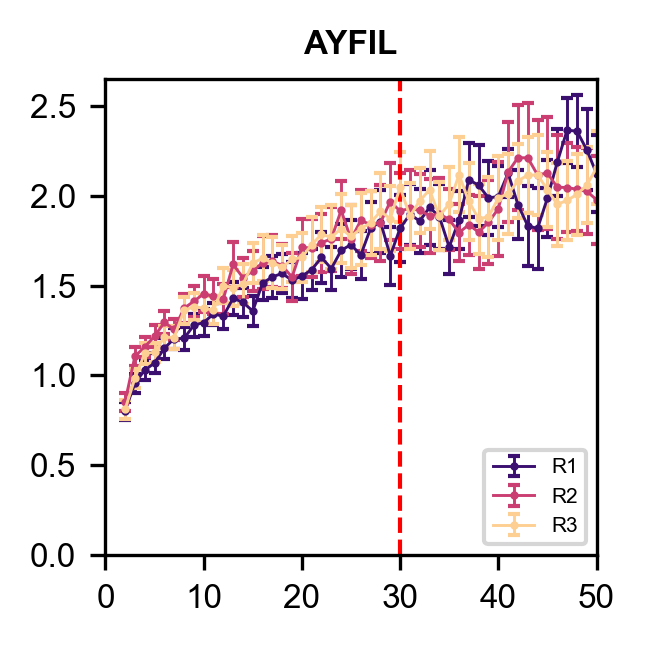

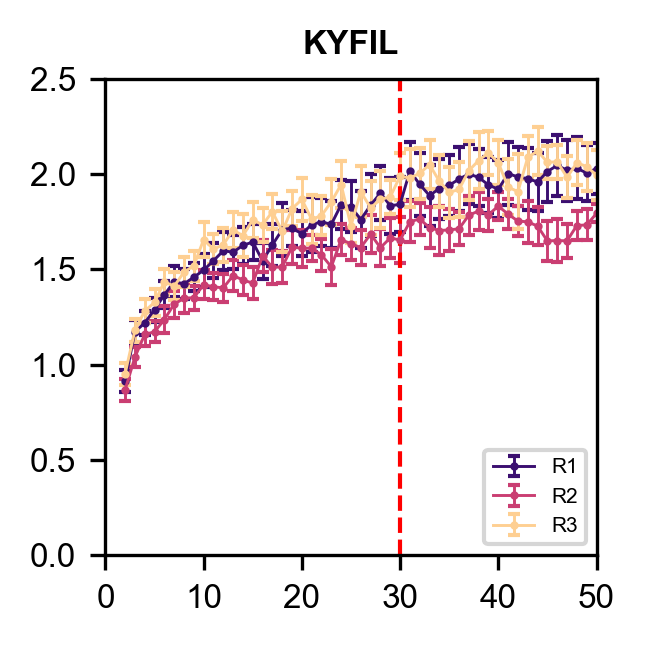

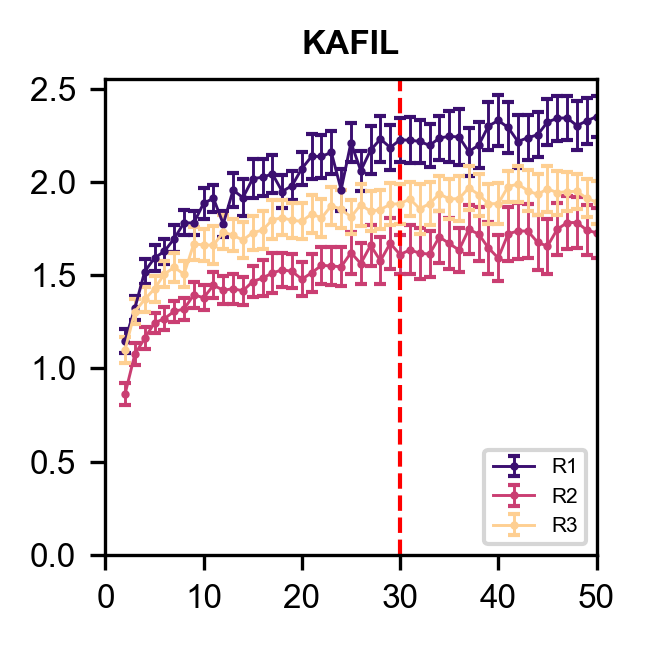

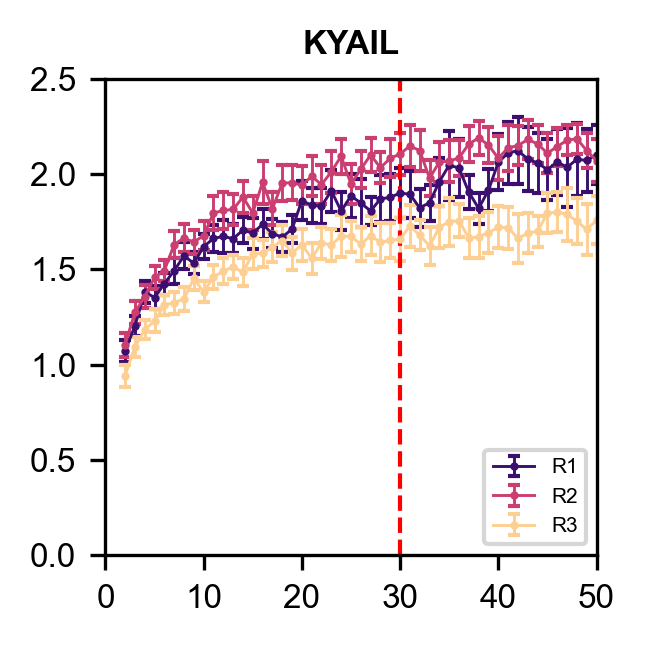

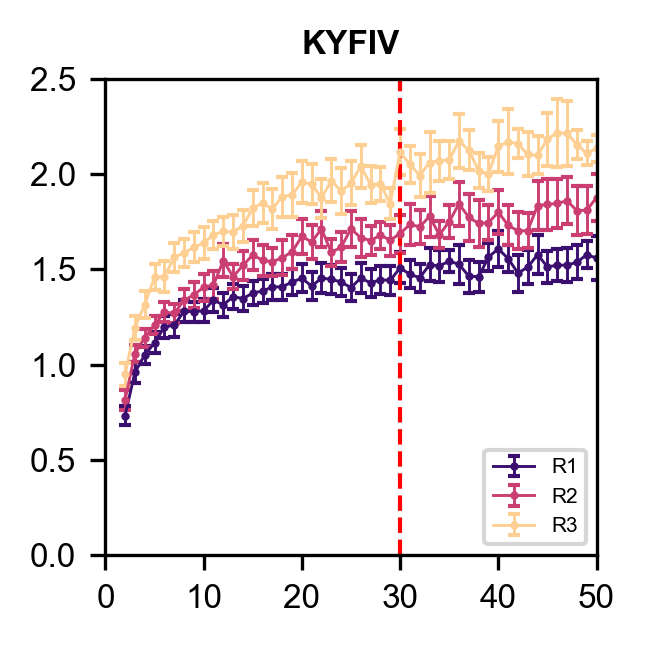

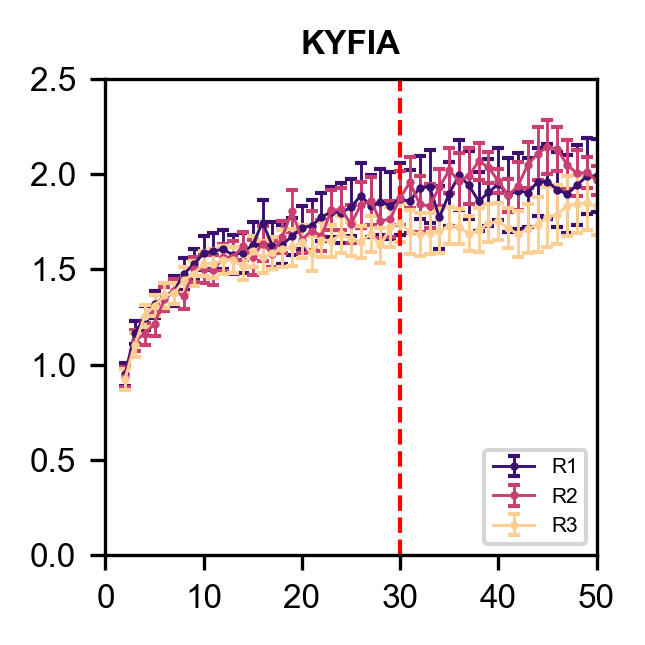

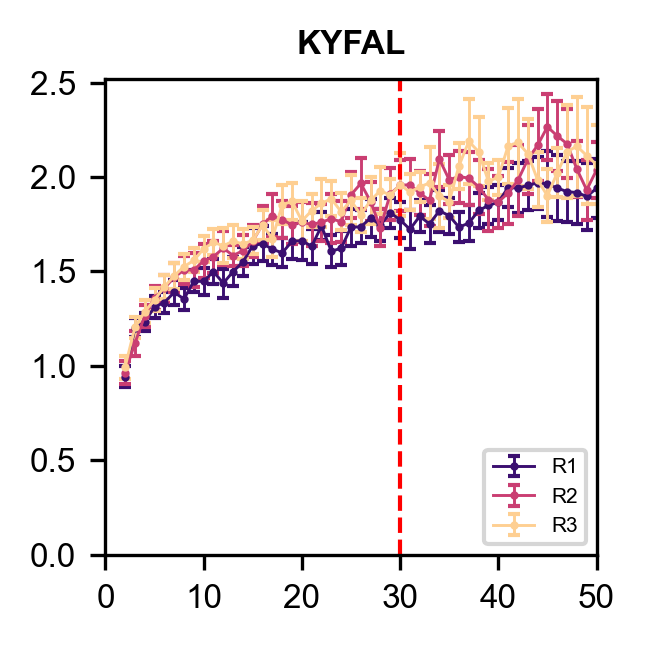

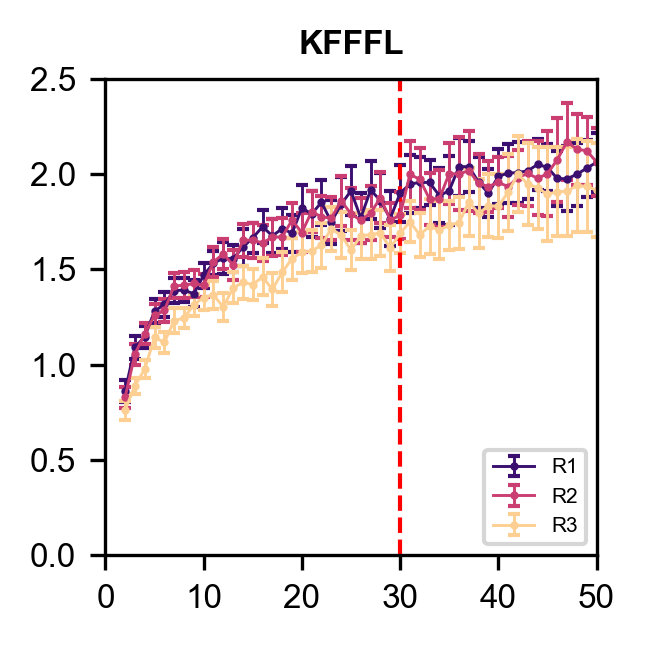

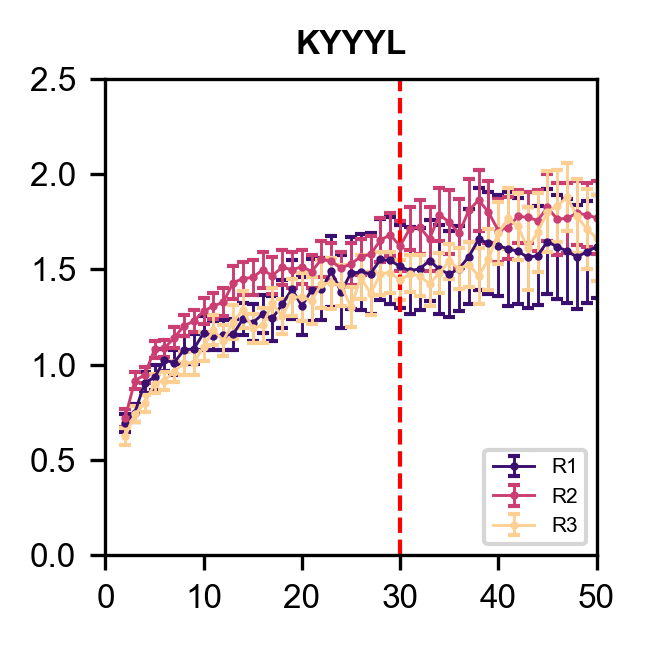

✅ Plots generated for all sequences!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import to_hex

# === Load the CSV file ===
cluster_data = pd.read_csv("num_clusters_over_time.csv")
cluster_data.columns = cluster_data.columns.str.strip()  # remove stray spaces

# === Settings ===
frames_per_point = 50
block_sizes_points = list(range(1, 51))  # block sizes 1–50
plt.rcParams.update({'font.family': 'Arial', 'font.size': 10})

# === Define helper functions ===
def calculate_std_and_error(data, block_size_points):
    num_blocks = len(data) // block_size_points
    if num_blocks < 2:
        return np.nan, np.nan
    std_devs = [
        np.std(data[i * block_size_points:(i + 1) * block_size_points], ddof=1)
        for i in range(num_blocks)
    ]
    std_devs = np.array(std_devs)
    return np.mean(std_devs), np.std(std_devs, ddof=1) / np.sqrt(num_blocks)

def compute_set_stats(data_set):
    means, errs = [], []
    for bs in block_sizes_points:
        m, e = calculate_std_and_error(data_set, bs)
        means.append(m)
        errs.append(e)
    return means, errs

# === Loop through each sequence ===
for sequence in cluster_data["Sequence"].unique():
    df_seq = cluster_data[cluster_data["Sequence"] == sequence]
    replicates = sorted(df_seq["Replicate"].unique())
    v_all = [df_seq[df_seq["Replicate"] == rep]["Num_Clusters"].values for rep in replicates]

    # Compute stats for all replicates
    means_all, errs_all = zip(*(compute_set_stats(v) for v in v_all))

    # Clean up NaNs (too-large block sizes)
    valid_indices = [i for i in range(len(means_all[0])) if not np.isnan(means_all[0][i])]
    block_sizes_ns = [block_sizes_points[i] for i in valid_indices]

    # === Plot setup ===
    fig, ax = plt.subplots(figsize=(2.25, 2.25), dpi=300)
    hex_colors = [to_hex(cm.magma(x)) for x in np.linspace(0.2, 0.9, len(replicates))]

    for i, (means, errs) in enumerate(zip(means_all, errs_all)):
        means_clean = [means[j] for j in valid_indices]
        errs_clean = [errs[j] for j in valid_indices]

        ax.errorbar(
            block_sizes_ns, means_clean, yerr=errs_clean, fmt='-o',
            label=f"{replicates[i]}",
            capsize=1.5,
            markersize=1,
            linewidth=0.7,
            color=hex_colors[i % len(hex_colors)]
        )

    # === Plot styling ===
    plt.axvline(x=30, color='red', linestyle='--', linewidth=1)
    plt.title(sequence, fontsize=8, fontdict={'family': 'Arial'}, fontweight='bold')
    ax.set_xlim(0, 50)
    ax.set_xticks(range(0, 51, 10))
    ax.set_yticks(np.arange(0, 2.6, 0.5))
    ax.tick_params(axis='both', labelsize=8)
    ax.legend(fontsize=5, loc='lower right', ncol=1)

    plt.tight_layout()
    #plt.savefig(f'std_vs_blocksize_{sequence}.png', dpi=300)
    plt.show(fig)

print("✅ Plots generated for all sequences!")
